# Шаг 4. Где сеть ошибается? Таблица путаницы и галерея ошибок

Точность 97% звучит хорошо, но одно число не говорит, **какие** ошибки делает сеть.
Чтобы понять это, строят **таблицу путаницы** (confusion matrix): сколько раз цифру `A` сеть приняла за цифру `B`.
А ещё полезно просто посмотреть на картинки, на которых сеть ошиблась.

> Нужна обученная сеть `mlp.pt` — сначала выполните ноутбук `03_train_mlp.ipynb`.

**Структура ноутбука (алгоритм):**
1. Загружаем обученную сеть и проверочный набор.
2. Получаем ответы сети на все 10 000 картинок, находим номера ошибочных.
3. Строим таблицу путаницы 10 × 10 одним приёмом с `bincount` и печатаем её.
4. Находим три самые частые путаницы.
5. Рисуем галерею из первых 24 ошибок и сохраняем в `mistakes.png`.

In [ ]:
# Настройка для Google Colab. На своём компьютере эта ячейка ничего не делает.
# В Colab нужна папка machine_vision на Google Диске (в ней session01–session05 и dataset).
import os
import sys

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive:
    drive.mount("/content/drive")
    COLAB_ROOT = "/content/drive/MyDrive/machine_vision"
    os.chdir(f"{COLAB_ROOT}/session03")  # здесь лежит common.py и сохраняются результаты
    sys.path.insert(0, os.getcwd())

    # Набор данных скачивается на Диск один раз, потом берётся готовый
    from torchvision import datasets

    datasets.MNIST(f"{COLAB_ROOT}/data", download=True)

## Общий модуль `common.py`

Во всех ноутбуках этой сессии используется модуль `common.py` из этой же папки:

| Имя | Что делает |
|-----|------------|
| `mnist(train)` | скачивает (один раз, ~12 МБ в папку `data`) и возвращает набор MNIST: обучающий (`train=True`, 60 000) или проверочный (`train=False`, 10 000) |
| `MLP` | многослойная сеть: 784 входа → 128 → 64 → 10 выходов |
| `train(model, dataset, epochs)` | цикл обучения из шага 3, без пояснений |
| `predict_all(model, dataset)` | ответы сети (номер цифры) для каждой картинки набора |
| `accuracy(model, dataset)` | доля картинок, на которых сеть ответила верно |
| `load_model()` | загрузить обученную сеть из `mlp.pt` (файл создаёт шаг 3) |
| `show()` | показать графики matplotlib и закрыть их |
| `MODEL_FILE` | путь к файлу `mlp.pt` |

> Ноутбуки нужно запускать из папки `session03`, иначе `import common` не найдёт модуль.
> Нужные библиотеки: `pip install -r requirements.txt`.

## 1. Загружаем сеть и данные

In [1]:
import matplotlib.pyplot as plt
import torch

from common import load_model, mnist, predict_all, show

model = load_model()
test = mnist(train=False)

## 2. Ответы сети и номера ошибок

- `predict_all` возвращает тензор из 10 000 ответов (номер цифры для каждой картинки).
- `test.targets` — правильные ответы.
- `predicted != truth` — булев тензор `True` там, где сеть ошиблась;
  `.nonzero()` даёт номера таких позиций (в виде столбца), `.flatten()` вытягивает их в простой список.

In [2]:
predicted = predict_all(model, test)
truth = test.targets
wrong = (predicted != truth).nonzero().flatten()
print(f"Ошибок: {len(wrong)} из {len(test)}")

Ошибок: 227 из 10000


## 3. Таблица путаницы

Хитрый приём, чтобы построить таблицу без циклов:
1. Каждой паре «(правильная цифра, ответ сети)» сопоставляем одно число `truth · 10 + predicted` — от 0 до 99.
   Например, пара (4 → 9) превращается в 49.
2. `torch.bincount(..., minlength=100)` считает, сколько раз встретилось каждое число от 0 до 99.
3. `.reshape(10, 10)` раскладывает 100 счётчиков в таблицу: **строка — правильная цифра, столбец — ответ сети**.

На **диагонали** (строка = столбец) стоят верные ответы, всё остальное — ошибки.

In [3]:
# Таблица путаницы: строка — правильная цифра, столбец — ответ сети
confusion = torch.bincount(truth * 10 + predicted, minlength=100).reshape(10, 10)
print("верно\\сеть " + "".join(f"{d:>5}" for d in range(10)))
for digit in range(10):
    print(f"{digit:>10} " + "".join(f"{n:>5}" for n in confusion[digit].tolist()))

верно\сеть     0    1    2    3    4    5    6    7    8    9
         0   970    0    1    2    0    1    2    1    3    0
         1     0 1122    2    3    0    0    2    1    4    1
         2     2    1  999   10    4    0    3    4    8    1
         3     0    0    3  988    0   11    0    3    1    4
         4     0    0    3    1  966    0    4    3    2    3
         5     2    0    0    4    0  879    2    1    3    1
         6     2    2    1    2    1    6  943    0    1    0
         7     2    2   10    6    1    1    0  996    5    5
         8     1    0    3   13    2    7    2    2  939    5
         9     0    2    0    4   12    7    2    5    6  971


## 4. Самые частые путаницы

1. Копируем таблицу (`clone`) и обнуляем диагональ (`fill_diagonal_(0)`) — остаются только ошибки.
2. `off.flatten()` — вытягиваем таблицу в список из 100 чисел, `argsort(descending=True)` — номера ячеек
   по убыванию, `[:3]` — три самые большие.
3. Номер ячейки `index` обратно превращаем в пару: `index // 10` — правильная цифра, `index % 10` — ответ сети.

In [4]:
# Самые частые путаницы (не считая диагонали — там верные ответы)
off = confusion.clone()
off.fill_diagonal_(0)
print("Чаще всего сеть путает:")
for index in off.flatten().argsort(descending=True)[:3].tolist():
    print(f"  {index // 10} → {index % 10}: {off.flatten()[index].item()} раз")

Чаще всего сеть путает:
  8 → 3: 13 раз
  9 → 4: 12 раз
  3 → 5: 11 раз


## 5. Галерея ошибок

Берём номера первых 24 ошибок и рисуем их в сетке 3 × 8. Подпись над картинкой: **правильная цифра → ответ сети**.
`zip(axes.flat, ...)` идёт по ячейкам и номерам одновременно; если ошибок меньше 24, лишние ячейки останутся пустыми.

Часть ошибок простительна: некоторые цифры и человек прочитает неуверенно.

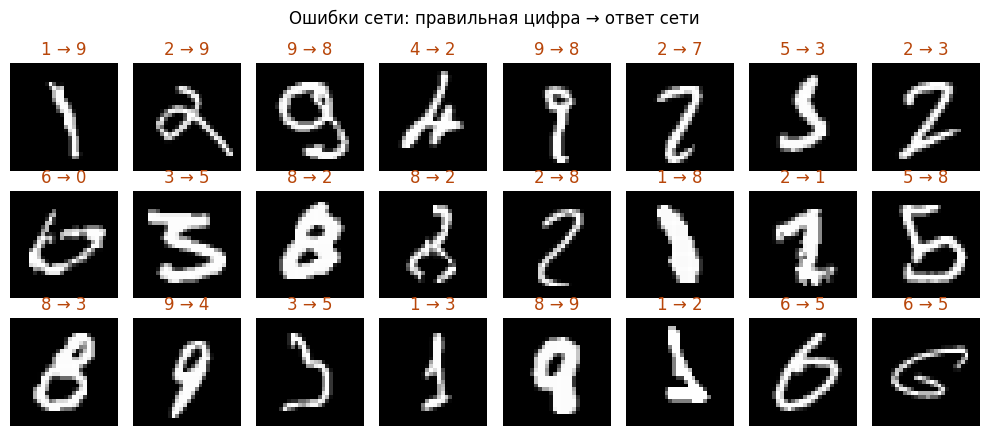

In [5]:
fig, axes = plt.subplots(3, 8, figsize=(10, 4.4))
for ax, i in zip(axes.flat, wrong[:24].tolist()):
    ax.imshow(test[i][0][0], cmap="gray")
    ax.set_title(f"{truth[i].item()} → {predicted[i].item()}", color="#B8460A")
    ax.axis("off")
fig.suptitle("Ошибки сети: правильная цифра → ответ сети")
plt.tight_layout()
plt.savefig("mistakes.png", dpi=100)
show()

## Попробуйте сами

1. Какую цифру сеть узнаёт хуже всего? Посчитайте точность по каждой строке: `confusion.diag() / confusion.sum(1)`.
2. Покажите ошибки только одного вида, например «4 → 9»: `((truth == 4) & (predicted == 9)).nonzero()`.
3. Нарисуйте таблицу путаницы как картинку: `plt.imshow(off)` с `plt.colorbar()`.
4. Какие из ошибок вы сами прочитали бы иначе, чем «правильный» ответ?